 Cargando dataset MNIST...
Datos de entrenamiento: (10000, 784)

 Experimento: Optimizadores y Learning Rate

 Entrenando con SGD (lr=0.01)...
   ✅ Accuracy: 0.8833 | Tiempo: 6.48s

 Entrenando con SGD (lr=0.1)...
   ✅ Accuracy: 0.9203 | Tiempo: 6.67s

 Entrenando con Adam (lr=0.001)...
   ✅ Accuracy: 0.9446 | Tiempo: 6.65s

 Entrenando con Adam (lr=0.1)...
   ✅ Accuracy: 0.8796 | Tiempo: 8.38s

Visualizando curvas de arendizaje


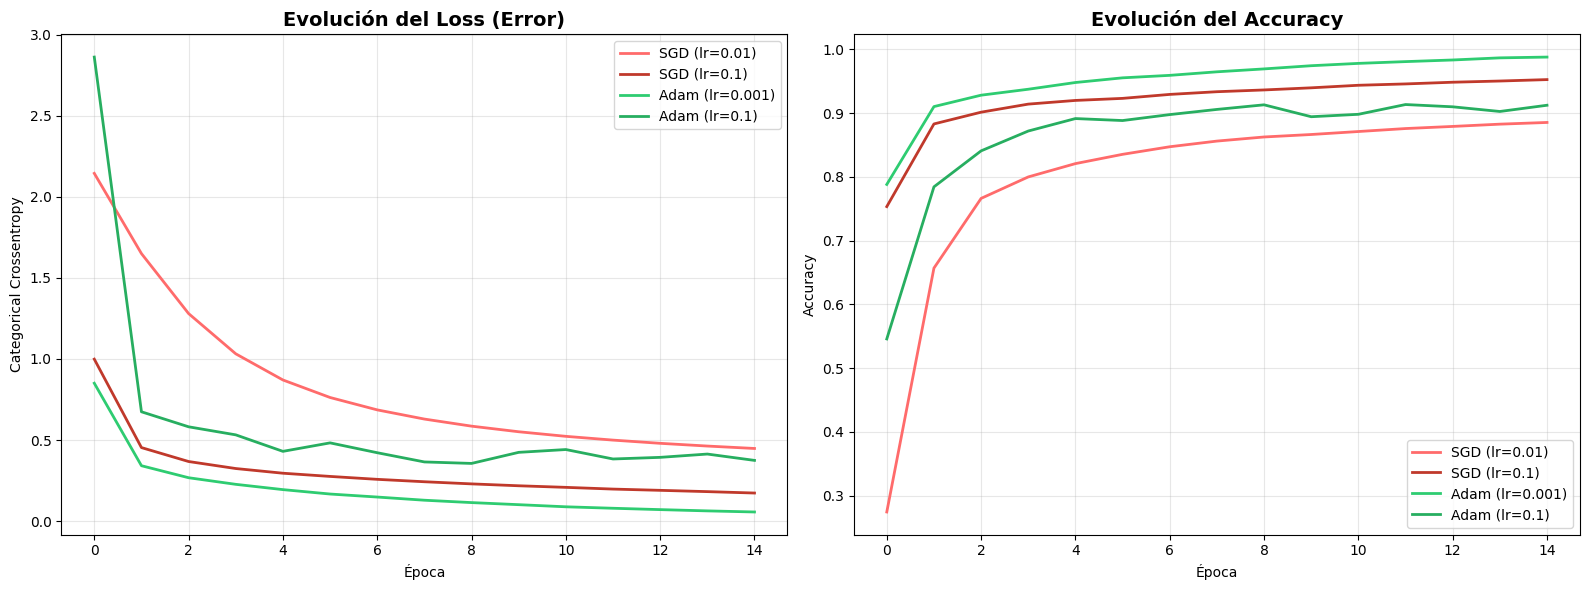


Resumen de resultados
  Configuración  Accuracy Test  Tiempo (s)
  SGD (lr=0.01)         0.8833    6.480669
   SGD (lr=0.1)         0.9203    6.674689
Adam (lr=0.001)         0.9446    6.651171
  Adam (lr=0.1)         0.8796    8.380211

Experimento extremo: LR = 1.0 (¡Explosión!)
Entrenando con SGD y lr=1.0 (prepárate para ver NaN)...
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


ValueError: Exception encountered when calling Sequential.call().

[1mInvalid input shape for input Tensor("data:0", shape=(None, 784), dtype=float32) with name 'keras_tensor_32' and path ''. Expected shape (None, 28, 28), but input has incompatible shape (None, 784)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 784), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos 'keras' directamente (es el estándar nuevo en Colab)
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Flatten, Input
from keras.optimizers import SGD, Adam
from keras.utils import to_categorical

import time


# 1. Cargar y preparar datos
print(" Cargando dataset MNIST...")
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalizar y aplanar
x_train_flat = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test_flat = x_test.reshape(-1, 784).astype('float32') / 255.0
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

# Usaremos un subset para que el entrenamiento sea rápido y visible
x_train_sub = x_train_flat[:10000]
y_train_sub = y_train_cat[:10000]

print(f"Datos de entrenamiento: {x_train_sub.shape}")



def train_model(optimizer, lr, epochs=15):
    """Crea, compila y entrena un modelo con los parámetros dados"""


    model = Sequential([
        Input(shape=(784,)),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print(f"\n Entrenando con {optimizer.__name__} (lr={lr})...")
    start_time = time.time()

    history = model.fit(
        x_train_sub, y_train_sub,
        epochs=epochs,
        batch_size=128,
        validation_split=0.1,
        verbose=0
    )

    train_time = time.time() - start_time
    _, test_acc = model.evaluate(x_test_flat, y_test_cat, verbose=0)

    return history, test_acc, train_time


# 3. Experimento: Comparar optimizadores
print("\n" + "="*70)
print(" Experimento: Optimizadores y Learning Rate")
print("="*70)

configuraciones = [
    {'nombre': 'SGD (lr=0.01)', 'opt': SGD, 'lr': 0.01, 'color': '#ff6b6b'},
    {'nombre': 'SGD (lr=0.1)', 'opt': SGD, 'lr': 0.1, 'color': '#c0392b'},
    {'nombre': 'Adam (lr=0.001)', 'opt': Adam, 'lr': 0.001, 'color': '#2ecc71'},
    {'nombre': 'Adam (lr=0.1)', 'opt': Adam, 'lr': 0.1, 'color': '#27ae60'}
]

resultados = []

for config in configuraciones:
    history, test_acc, train_time = train_model(
        optimizer=config['opt'],
        lr=config['lr'],
        epochs=15
    )

    resultados.append({
        'Configuración': config['nombre'],
        'Accuracy Test': test_acc,
        'Tiempo (s)': train_time,
        'history': history,
        'color': config['color']
    })

    print(f"   ✅ Accuracy: {test_acc:.4f} | Tiempo: {train_time:.2f}s")


# 4. Visualización curvas aprendizaje
print("\n" + "="*70)
print("Visualizando curvas de arendizaje")
print("="*70)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Loss (Pérdida)
for res in resultados:
    axes[0].plot(res['history'].history['loss'],
                 label=res['Configuración'],
                 color=res['color'], linewidth=2)

axes[0].set_title('Evolución del Loss (Error)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Categorical Crossentropy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Accuracy (Precisión)
for res in resultados:
    axes[1].plot(res['history'].history['accuracy'],
                 label=res['Configuración'],
                 color=res['color'], linewidth=2)

axes[1].set_title('Evolución del Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 5. Tabla Resumen
df_resumen = pd.DataFrame([{
    'Configuración': r['Configuración'],
    'Accuracy Test': r['Accuracy Test'],
    'Tiempo (s)': r['Tiempo (s)']
} for r in resultados])

print("\n" + "="*70)
print("Resumen de resultados")
print("="*70)
print(df_resumen.to_string(index=False))


# 6. Experimento extremo: Learning Rate Demasiado Alto
print("\n" + "="*70)
print("Experimento extremo: LR = 1.0 (¡Explosión!)")
print("="*70)

print("Entrenando con SGD y lr=1.0 (prepárate para ver NaN)...")
model_extremo = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_extremo.compile(
    optimizer=SGD(learning_rate=1.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_extremo = model_extremo.fit(
    x_train_sub, y_train_sub,
    epochs=3,
    batch_size=128,
    verbose=1
)


# 7. Lecciónes Clave
print("\n" + "="*70)
print("Lecciones clave del dia 16")
print("="*70)

print("""
1. La Función de Loss es tu brújula:
   - Si el Loss baja, el modelo aprende.
   - Si el Loss sube o se vuelve 'NaN', el Learning Rate es demasiado alto.

2. Backpropagation es el motor:
   - Calcula el gradiente (la pendiente) del error respecto a cada peso.
   - Sin ella, la red no sabría cómo ajustarse.

3. Adam vs SGD:
   - SGD es inestable con LR altos y lento en converger.
   - Adam adapta el LR por cada peso, convergiendo más rápido y estable.
   - Por eso Adam es el default en el 95% de los proyectos.

4. El Learning Rate es el hiperparámetro MÁS importante:
   - Demasiado alto → Divergencia (Loss explota).
   - Demasiado bajo → Estancamiento (aprende muy lento).
   - Regla de oro: Empieza con Adam y lr=0.001.

5. Overfitting en entrenamiento:
   - Si 'loss' (train) sigue bajando pero 'val_loss' (validación) sube,
     ¡tu modelo está memorizando, no aprendiendo! (Necesitas Dropout o Early Stopping).
""")

print("\n✅ Día 16 completado!")